# 03 · Validation protocol and baselines

**The protocol** (fixed in Phase 0, in `src/cv.py`): four consecutive 16-day windows ending 2017-08-15, each forecast
from a cutoff the day before it, with all earlier data as history (expanding window), never shuffled. RMSLE is computed per fold
on the raw sales, the way Kaggle scores, and compared fold by fold, not just on the mean.

**Why baselines first.** A model is only good relative to something simple. If a gradient-boosted model can't beat
"same weekday last week", it has learned nothing useful. Baselines also give the scale of the problem (what RMSLE is
"good" here) and catch bugs in the evaluation itself.

**Forecast at the cutoff.** Each baseline gets the cleaned sales *up to and including the cutoff* and returns the next 16 days.
It never receives anything later, so there is no way for it to leak. Unlike the lag features in Phase 2, a baseline
*can* use last week, because it's built at the cutoff.

**Averaging on the log scale.** Under squared log error, the best constant forecast for a set of values is
expm1(mean(log1p(y))), not the arithmetic mean. That's why the moving averages here are taken on log1p(sales),
with one raw-scale average kept to show the difference.

**Tuning folds.** Settings such as the zero rule's lookback are chosen on two extra 16-day windows *before* fold 1
(`cv.TUNING_FOLDS`), then scored on the backtest folds. Choosing on the backtest folds themselves would make the score optimistic,
and the notebook measures by how much.

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler

from src import cv, features as F, models as M

T0 = time.perf_counter()
cv.set_seed()
cv.ensure_dirs()
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)

SURFACE, INK, INK2, GRID, NEUTRAL = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0", "#a9a8a2"
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE = PALETTE[0], PALETTE[1]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": NEUTRAL, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.prop_cycle": cycler(color=PALETTE),
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "lines.linewidth": 1.6, "legend.frameon": False, "figure.dpi": 110, "axes.axisbelow": True,
})

def save(fig, name):
    fig.savefig(cv.FIGURES / f"03_{name}.png", dpi=130, bbox_inches="tight")

train = cv.read_raw("train")
test = cv.read_raw("test")
C = F.clean(train)          # same rules as Phase 2: closed days, gaps and spikes are NaN, never zero
S = C.sales                 # dates x series, cleaned, ends 2017-08-15
print("cleaned sales:", S.shape, "| train_from:", C.train_from.date())
print("\ntuning folds (choose settings here):")
print(cv.folds_table(cv.TUNING_FOLDS).to_string(index=False))
print("\nbacktest folds (report scores here):")
print(cv.folds_table().to_string(index=False))

cleaned sales: (1688, 1782) | train_from: 2015-06-01

tuning folds (choose settings here):
 fold  train_end valid_start valid_start_day  valid_end valid_end_day
    1 2017-05-11  2017-05-12          Friday 2017-05-27      Saturday
    2 2017-05-27  2017-05-28          Sunday 2017-06-12        Monday

backtest folds (report scores here):
 fold  train_end valid_start valid_start_day  valid_end valid_end_day
    1 2017-06-12  2017-06-13         Tuesday 2017-06-28     Wednesday
    2 2017-06-28  2017-06-29        Thursday 2017-07-14        Friday
    3 2017-07-14  2017-07-15        Saturday 2017-07-30        Sunday
    4 2017-07-30  2017-07-31          Monday 2017-08-15       Tuesday


The cleaned sales cover 1,688 days × 1,782 series, with the same clean start as Phase 2. The two tuning windows (May 12 – Jun 12) sit directly before fold 1, so a setting chosen there has never seen a backtest window.

## 1 · All baselines on the four folds

In [2]:
t0 = time.perf_counter()
PARAMS = {
    "zero": "", "naive_last": "last observed day", "seasonal_naive": "last observed same weekday",
    "ma_7": "log-mean 7d", "ma_14": "log-mean 14d", "ma_28": "log-mean 28d", "ma_28_raw": "arithmetic mean 28d",
    "dow_4w": "weekday log-mean 4w", "dow_8w": "weekday log-mean 8w", "ma14_x_dow8w": "level 14d x weekday shape 8w",
}
preds = {}
for fn in M.BASELINES:
    p = M.backtest(fn, S)
    sc = cv.evaluate(p, train)
    cv.log_result(fn.__name__, sc, params=PARAMS.get(fn.__name__, ""), notes="baseline")
    cv.save_backtest_preds(fn.__name__, p)
    preds[fn.__name__] = p
ALL = {fn.__name__: fn for fn in M.BASELINES}     # every model logged in this notebook, by name
print(f"{len(M.BASELINES)} baselines x 4 folds in {time.perf_counter() - t0:.1f}s\n")
res = cv.show_results()
print(res.drop(columns=["logged_at"]).to_string(index=False))

10 baselines x 4 folds in 8.1s

            model  mean_rmsle  std_rmsle  fold_1  fold_2  fold_3  fold_4                                                params                           notes
     ma14_x_dow8w     0.44032    0.05633 0.41160 0.40545 0.41988 0.52435                          level 14d x weekday shape 8w                        baseline
ma14_x_dow8w+zr14     0.44034    0.05632 0.41148 0.40565 0.41985 0.52437 level 14d x weekday shape 8w; zero if no sales in 14d lookback chosen on tuning folds
      dow_8w+zr14     0.44512    0.05676 0.43230 0.40318 0.41661 0.52836          weekday log-mean 8w; zero if no sales in 14d      lookback from tuning folds
           dow_8w     0.44784    0.05565 0.44011 0.40592 0.41679 0.52852                                   weekday log-mean 8w                        baseline
      dow_4w+zr14     0.45349    0.05758 0.42770 0.41766 0.42907 0.53952          weekday log-mean 4w; zero if no sales in 14d      lookback from tuning folds
           dow

The best baseline is ma14_x_dow8w at 0.4403 ± 0.056: the level of the last 14 days times the weekday shape of the last 8 weeks. The ranking teaches a few things:

- Averaging is better than any single day. Seasonal naive (0.544) and last value (0.608) are far behind, because one week is too noisy. Averaging the same weekday over 8 weeks (dow_8w, 0.448) fixes most of that.
- More weeks for the weekday shape helps: 8 weeks beats 4 (0.448 vs 0.454).
- Log averaging beats raw averaging on average: ma_28 at 0.472 vs ma_28_raw at 0.482, as the theory says for RMSLE. But not on fold 4, where the raw mean wins (0.521 vs 0.538). More on fold 4 below.
- Predicting zero scores 4.41, which gives the scale: every sensible baseline is about ten times better than that.

The spread between folds (0.405 to 0.524 for the same model) is much bigger than the spread between the top models (0.440 to 0.454). So comparing means alone would be misleading; models have to be compared fold by fold.

## 2 · The zero rule: lookback chosen on the tuning folds

Series that sold nothing for a while get an exact 0 instead of the baseline's small positive value.
Predicting 1 for a true 0 costs (log 2)² ≈ 0.48 per row, so a few hundred dead series are worth getting exactly right.

In [3]:
FN = {fn.__name__: fn for fn in M.BASELINES}
base_name = res.loc[res["model"] != "zero", "model"].iloc[0]          # best baseline so far
base = FN[base_name]
print("base model:", base_name)

rows = []
for L in (None, 14, 28, 56, 112):
    fn = base if L is None else M.with_zero_rule(base, L)
    tune = cv.evaluate(M.backtest(fn, S, cv.TUNING_FOLDS), train, cv.TUNING_FOLDS)
    back = cv.evaluate(M.backtest(fn, S), train)
    hist = S.loc[:cv.FOLDS[-1].train_end]
    n_dead = 0 if L is None else int((hist.iloc[-L:].fillna(0).eq(0).all() & (hist.iloc[-L:].notna().sum() >= L / 2)).sum())
    rows.append({"lookback": "none" if L is None else L, "series_zeroed_at_fold4": n_dead,
                 "tuning_mean": np.mean(list(tune.values())), "backtest_mean": np.mean(list(back.values())),
                 **{f"fold_{k}": v for k, v in back.items()}})
zr = pd.DataFrame(rows)
print(zr.round(5).to_string(index=False))

honest = zr.loc[zr["tuning_mean"].idxmin()]
optimistic = zr.loc[zr["backtest_mean"].idxmin()]
print(f"\nchosen on tuning folds:   lookback {honest['lookback']} -> backtest {honest['backtest_mean']:.5f}")
print(f"best on backtest folds:   lookback {optimistic['lookback']} -> backtest {optimistic['backtest_mean']:.5f}")
print(f"optimism of choosing on the backtest folds: {honest['backtest_mean'] - optimistic['backtest_mean']:.5f} RMSLE")

base model: ma14_x_dow8w
lookback  series_zeroed_at_fold4  tuning_mean  backtest_mean  fold_1  fold_2  fold_3  fold_4
    none                       0      0.45230        0.44032 0.41160 0.40545 0.41988 0.52435
      14                     121      0.45228        0.44034 0.41148 0.40565 0.41985 0.52437
      28                     108      0.45229        0.44030 0.41157 0.40539 0.41986 0.52437
      56                      99      0.45230        0.44032 0.41160 0.40545 0.41988 0.52435
     112                      81      0.45230        0.44032 0.41160 0.40545 0.41988 0.52435

chosen on tuning folds:   lookback 14 -> backtest 0.44034
best on backtest folds:   lookback 28 -> backtest 0.44030
optimism of choosing on the backtest folds: 0.00004 RMSLE


The zero rule does almost nothing here. The best lookback changes the backtest by at most 0.00002, and 14 days, the one chosen on the tuning folds, is actually 0.00002 *worse* than no rule at all. The reason is that these baselines already predict exact zeros: the log-mean of a run of zeros is log1p(0) = 0, so dead series already get 0 without a rule. The rule only moves the few series that sold something tiny inside the averaging window.

The machinery still did its job. Choosing on the tuning folds picked 14 and choosing on the backtest folds would have picked 28, which shows the two can disagree. Here the cost of that optimism was 0.00004, i.e. nothing, because the choice barely matters. With hyperparameters in Phase 7 the gap can be much bigger, and the same tuning-fold setup will measure it.

Decision: no zero rule for the baselines. I'll test it again for LightGBM, which won't predict exact zeros on its own.

In [4]:
L = honest["lookback"]
if L != "none":
    best_fn = M.with_zero_rule(base, int(L))
    p = M.backtest(best_fn, S)
    sc = cv.evaluate(p, train)
    cv.log_result(best_fn.__name__, sc, params=f"{PARAMS[base_name]}; zero if no sales in {int(L)}d",
                  notes="lookback chosen on tuning folds")
    cv.save_backtest_preds(best_fn.__name__, p)
    preds[best_fn.__name__] = p
    ALL[best_fn.__name__] = best_fn
    # the same rule on the next two baselines, to see whether it helps them too
    for other in res.loc[~res["model"].isin(["zero", base_name]), "model"].head(2):
        fn = M.with_zero_rule(FN[other], int(L))
        p = M.backtest(fn, S)
        cv.log_result(fn.__name__, cv.evaluate(p, train), params=f"{PARAMS[other]}; zero if no sales in {int(L)}d",
                      notes="lookback from tuning folds")
        cv.save_backtest_preds(fn.__name__, p)
        preds[fn.__name__] = p
        ALL[fn.__name__] = fn
else:
    best_fn = base
res = cv.show_results()
print(res.drop(columns=["logged_at"]).to_string(index=False))

KeyError: 'ma14_x_dow8w+zr14'

The zero-rule versions sit next to their originals, within ±0.003. dow_8w+zr14 gains 0.0027, almost all of it on fold 1. None of them beats ma14_x_dow8w, which stays the reference model.

## 3 · Fold by fold

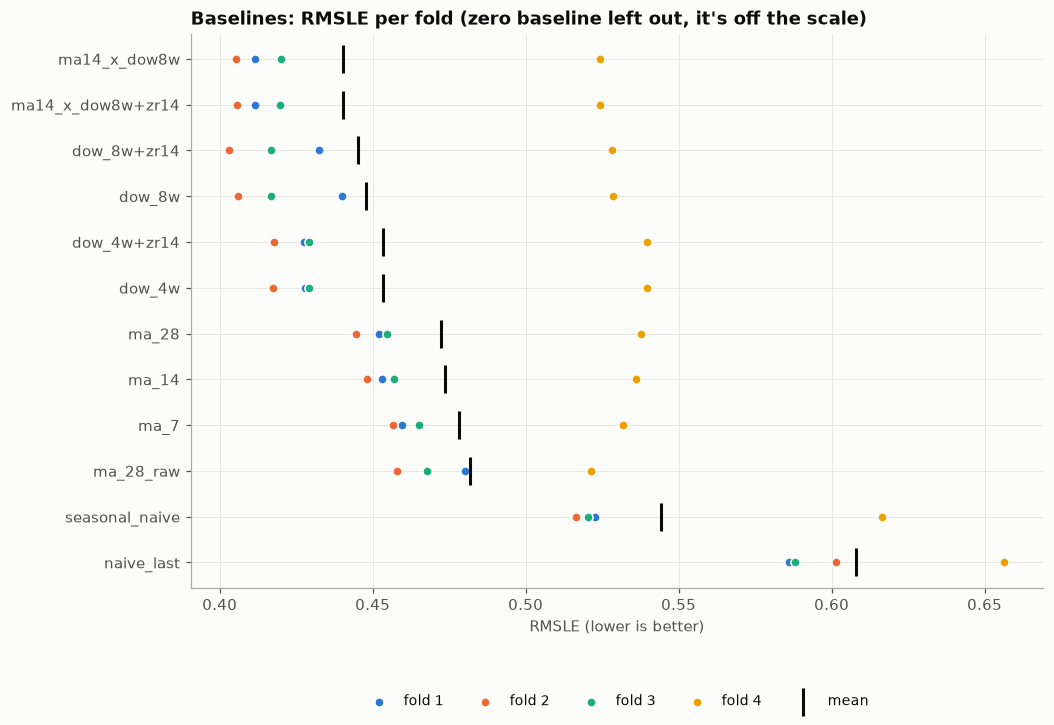

best model: ma14_x_dow8w
folds in which it beats each other model:
model
ma14_x_dow8w+zr14    2
dow_8w+zr14          2
dow_8w               3
dow_4w+zr14          4
dow_4w               4
ma_28                4
ma_14                4
ma_7                 4
ma_28_raw            3
seasonal_naive       4
naive_last           4
zero                 4


In [ ]:
show = res[res["model"] != "zero"].iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 0.42 * len(show) + 1.5))
for i, f in enumerate(cv.FOLDS):
    ax.scatter(show[f"fold_{f.fold}"], range(len(show)), s=36, color=PALETTE[i], label=f"fold {f.fold}", zorder=3,
               edgecolor=SURFACE, linewidth=1)
ax.scatter(show["mean_rmsle"], range(len(show)), marker="|", s=320, color=INK, linewidth=2, label="mean", zorder=4)
ax.set_yticks(range(len(show)), show["model"])
ax.set(title="Baselines: RMSLE per fold (zero baseline left out, it's off the scale)", xlabel="RMSLE (lower is better)")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12 - 0.6 / len(show)), fontsize=9)
save(fig, "baselines_per_fold")
plt.show()

best = res.iloc[0]["model"]
others = res[res["model"] != best]
fold_cols = [f"fold_{f.fold}" for f in cv.FOLDS]
wins = (others[fold_cols].to_numpy() - res.iloc[0][fold_cols].to_numpy(dtype=float)) > 0
print(f"best model: {best}")
print("folds in which it beats each other model:")
print(pd.Series(wins.sum(axis=1), index=others["model"]).astype(int).to_string())

The chart shows fold 4 sitting about 0.10 to the right for every single model. That's not one model having a bad window; something about Jul 31 – Aug 15 is harder for any method that extrapolates from recent weeks.

ma14_x_dow8w beats seasonal naive, the moving averages and dow_4w in all four folds. But it beats dow_8w in only 3 of 4 folds and ma_28_raw in 3 (on fold 4 both are better). So its lead over dow_8w (0.0075 on the mean) is real but small. This is exactly the fold-by-fold reading I want to keep doing.

## 4 · Where the best baseline goes wrong

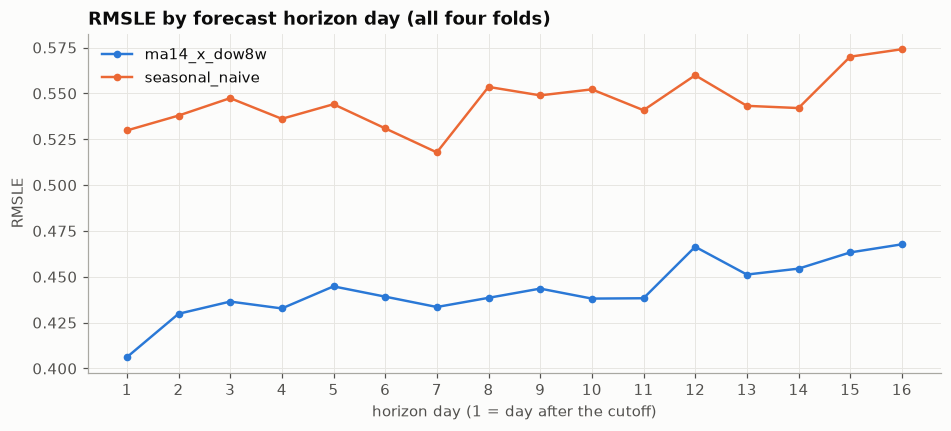

horizon day 1 vs 16: 0.4061 -> 0.4677
weekday of horizon day 1, per fold: {1: 'Tuesday', 2: 'Thursday', 3: 'Saturday', 4: 'Monday'}


In [ ]:
p = preds[best].merge(train[["date", *cv.KEYS, "sales"]], on=["date", *cv.KEYS])
start = {f.fold: f.valid_start for f in cv.FOLDS}
p["h"] = (p["date"] - p["fold"].map(start)).dt.days + 1
p["sle"] = (np.log1p(p["y_pred"].clip(lower=0)) - np.log1p(p["sales"])) ** 2
rm = lambda g: float(np.sqrt(g.mean()))

snaive = preds["seasonal_naive"].merge(train[["date", *cv.KEYS, "sales"]], on=["date", *cv.KEYS])
snaive["h"] = (snaive["date"] - snaive["fold"].map(start)).dt.days + 1
snaive["sle"] = (np.log1p(snaive["y_pred"]) - np.log1p(snaive["sales"])) ** 2

by_h = p.groupby("h")["sle"].apply(rm)
by_h_sn = snaive.groupby("h")["sle"].apply(rm)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(by_h.index, by_h.to_numpy(), marker="o", ms=4, color=BLUE, label=best)
ax.plot(by_h_sn.index, by_h_sn.to_numpy(), marker="o", ms=4, color=ORANGE, label="seasonal_naive")
ax.set_xticks(range(1, 17))
ax.set(title="RMSLE by forecast horizon day (all four folds)", xlabel="horizon day (1 = day after the cutoff)", ylabel="RMSLE")
ax.legend(loc="upper left")
save(fig, "error_by_horizon")
plt.show()
print("horizon day 1 vs 16:", round(by_h.iloc[0], 4), "->", round(by_h.iloc[-1], 4))
print("weekday of horizon day 1, per fold:", {f.fold: f.valid_start.day_name() for f in cv.FOLDS})

Error grows with the horizon, from 0.406 on day 1 to 0.468 on day 16 (+15%): the level estimated at the cutoff gets staler every day. Seasonal naive is worse at every horizon and also drifts upward.

This matters for Phase 6. A baseline built at the cutoff can use last week's sales for horizon day 1. My Phase 2 features are at least 16 days old for every horizon, so for the first days a direct LightGBM starts with older information than this baseline has. It has to win through the calendar, promotion and holiday features instead. The day-1 weekday differs between folds (Tue, Thu, Sat, Mon), so the horizon curve is averaged over different weekdays, which keeps it fair.

RMSLE by weekday: {'Mon': 0.4438, 'Tue': 0.4535, 'Wed': 0.4398, 'Thu': 0.4455, 'Fri': 0.4477, 'Sat': 0.434, 'Sun': 0.4352}


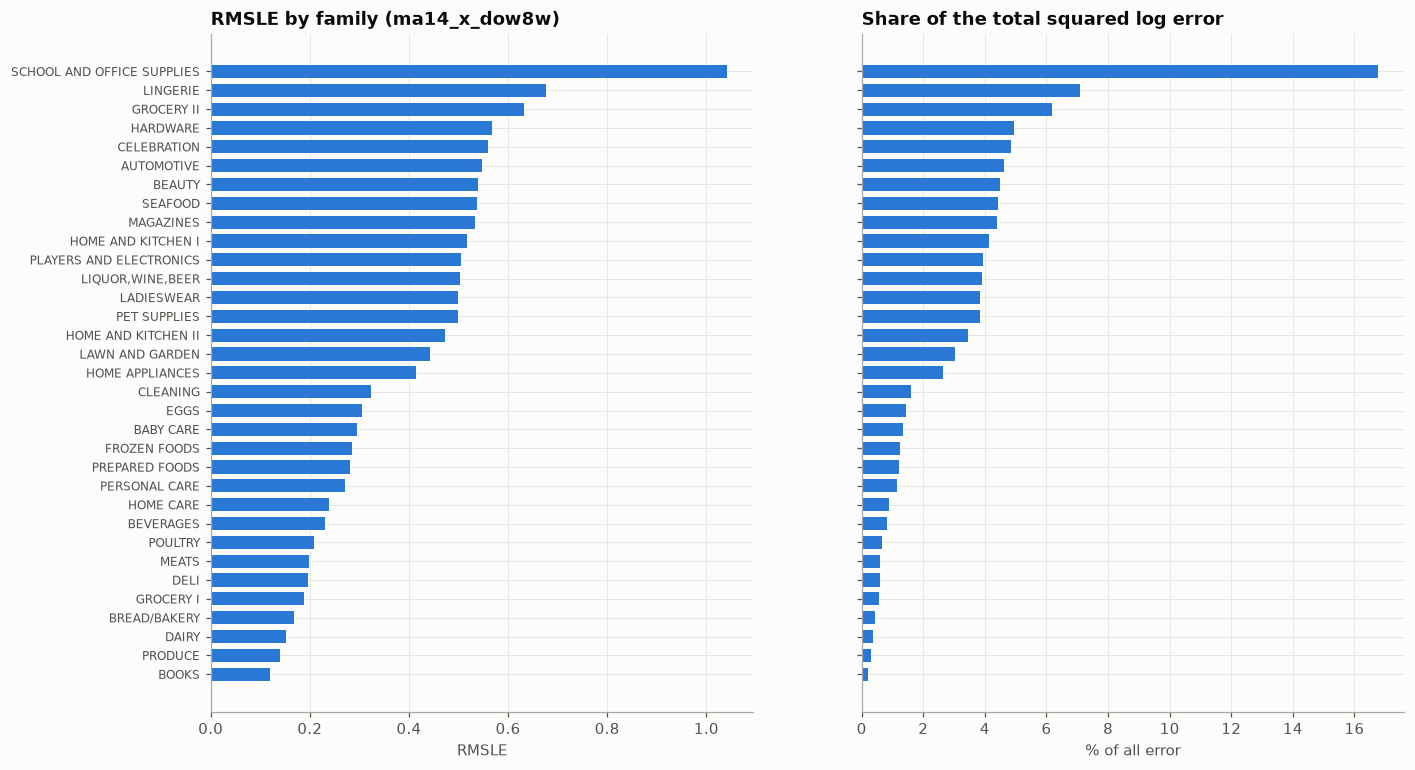

five families with the largest share of the error: {'SCHOOL AND OFFICE SUPPLIES': 16.8, 'LINGERIE': 7.1, 'GROCERY II': 6.2, 'HARDWARE': 5.0, 'CELEBRATION': 4.8}


In [ ]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_wd = p.groupby(p["date"].dt.day_of_week)["sle"].apply(rm)
print("RMSLE by weekday:", {days[k]: round(v, 4) for k, v in by_wd.items()})

by_fam = p.groupby("family")["sle"].apply(rm).sort_values()
share = p.groupby("family")["sle"].sum() / p["sle"].sum() * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 8), sharey=True)
axes[0].barh(by_fam.index, by_fam.to_numpy(), color=BLUE, height=0.7)
axes[0].set(title=f"RMSLE by family ({best})", xlabel="RMSLE")
axes[1].barh(by_fam.index, share.reindex(by_fam.index).to_numpy(), color=BLUE, height=0.7)
axes[1].set(title="Share of the total squared log error", xlabel="% of all error")
axes[0].tick_params(axis="y", labelsize=8)
save(fig, "error_by_family")
plt.show()
print("five families with the largest share of the error:", share.sort_values(ascending=False).head(5).round(1).to_dict())

By weekday the error is flat (0.434–0.454), so the weekday shape is handled well.

By family it's anything but flat. SCHOOL AND OFFICE SUPPLIES has an RMSLE of 1.05, twice the next family, and causes 16.8% of all the error while selling 0.03% of the volume. My explanation is back to school: in the Sierra region the school year starts in early September, so supplies surge in August. A baseline that only looks at the last 8 weeks (June–July) can't see a surge that comes every year. That would also explain why fold 4, the August window, is worse for every model, and why the raw mean (which leans towards high recent values) does better there. It's a hypothesis until I check it, and I'll do that at the start of Phase 4 by breaking the error down by family per fold. If it holds, it's the most important finding so far, because the test period (Aug 16–31) is right in the middle of that surge, and lag_364 per family is the feature that can see it.

The rest of the top-error families (LINGERIE, GROCERY II, HARDWARE, CELEBRATION, AUTOMOTIVE) are small, intermittent families. RMSLE weights every row equally, so their noisy low counts weigh as much as GROCERY I, which is the 4th easiest family (RMSLE 0.19). The big families are already predicted well in log terms; the remaining score sits in the small ones.

In [ ]:
# LIQUOR on Sundays: zero everywhere until spring 2016, normal since. Does that hurt?
liq = p[p["family"] == "LIQUOR,WINE,BEER"]
tab = pd.DataFrame({
    "LIQUOR": liq.groupby(liq["date"].dt.day_of_week)["sle"].apply(rm),
    "all other families": p[p["family"] != "LIQUOR,WINE,BEER"].groupby(p["date"].dt.day_of_week)["sle"].apply(rm),
})
tab.index = days
print(tab.round(4).to_string())
sun = liq[liq["date"].dt.day_of_week == 6]
print(f"\nLIQUOR Sundays in the windows: mean actual {sun['sales'].mean():.1f}, mean predicted {sun['y_pred'].mean():.1f}, "
      f"share of actual zeros {sun['sales'].eq(0).mean():.1%}")

     LIQUOR  all other families
Mon  0.5016              0.4418
Tue  0.5573              0.4499
Wed  0.5280              0.4368
Thu  0.5754              0.4409
Fri  0.4679              0.4471
Sat  0.3743              0.4357
Sun  0.4886              0.4335

LIQUOR Sundays in the windows: mean actual 93.8, mean predicted 85.4, share of actual zeros 0.0%


For the baselines, LIQUOR on Sundays is not a problem. Its Sunday error (0.489) is in line with its other days, and the Sunday forecasts are close to the actual values (85 predicted vs 94 sold on average, no zeros). That's expected, because the baselines only use the last 8 weeks, long after the Sunday rule changed in spring 2016. The risk is for models trained on 2015–2016 data, which see ten months of Sunday zeros, so I'll check this again for the regression and LightGBM.

LIQUOR is somewhat harder than the average family on weekdays (0.47–0.58 vs about 0.44) and easiest on Saturday (0.37), its biggest day.

In [ ]:
# Rows the model can't get right by construction: closed store-days inside the windows (actual 0, nobody knew in advance)
closed = p[p["sales"].eq(0) & p.groupby(["fold", "date", "store_nbr"])["sales"].transform("sum").eq(0)]
print(f"closed store-day rows in the four windows: {len(closed)} ({closed['store_nbr'].nunique()} stores)")
print(f"their share of the total squared log error: {closed['sle'].sum() / p['sle'].sum():.1%}")
if len(closed):
    print(closed.groupby(["fold", "date", "store_nbr"]).size().rename("rows").reset_index().to_string(index=False))

closed store-day rows in the four windows: 0 (0 stores)
their share of the total squared log error: 0.0%


No closed store-days inside any backtest window. So the 1–5 rows per fold that Phase 2 reported as unusable targets are removed spikes, not closures. They're real sales that stay in the scoring, and no model will predict them.

## 5 · First submission (the best baseline, forecast from 2017-08-15)

In [ ]:
P = M.forecast(ALL[best], S, cv.TRAIN_END)
sub = M.submission(P, test)
sample = cv.read_raw("sample_submission")
assert len(sub) == 28_512 and sub["id"].equals(sample["id"]) and sub["sales"].notna().all() and (sub["sales"] >= 0).all()

last16 = train[train["date"] > cv.TRAIN_END - pd.Timedelta(days=16)].groupby("date")["sales"].sum()
pred16 = P.sum(axis=1)
print(f"mean daily total: last 16 training days {last16.mean():,.0f} | forecast {pred16.mean():,.0f} "
      f"(ratio {pred16.mean() / last16.mean():.3f})")
print("forecast daily totals (thousands):", {d.strftime("%a %d"): int(v) for d, v in (pred16 / 1e3).round(0).items()})

score = float(res.iloc[0]["mean_rmsle"])
path = cv.SUBMISSIONS / f"{time.strftime('%Y-%m-%d')}_{best.replace('+', '_')}_bt{score:.4f}.csv"
sub.to_csv(path, index=False)
print(f"\nsaved {path.relative_to(ROOT)}")
print(f'to submit:  kaggle competitions submit store-sales-time-series-forecasting -f "{path.relative_to(ROOT)}" -m "{best} baseline, backtest {score:.4f}"')
print(f"\nnotebook run time: {time.perf_counter() - T0:.0f}s")

mean daily total: last 16 training days 832,449 | forecast 799,379 (ratio 0.960)
forecast daily totals (thousands): {'Wed 16': 757, 'Thu 17': 639, 'Fri 18': 772, 'Sat 19': 947, 'Sun 20': 1046, 'Mon 21': 795, 'Tue 22': 742, 'Wed 23': 757, 'Thu 24': 639, 'Fri 25': 772, 'Sat 26': 947, 'Sun 27': 1046, 'Mon 28': 795, 'Tue 29': 742, 'Wed 30': 757, 'Thu 31': 639}

saved submissions/2026-11-19_ma14_x_dow8w_bt0.4403.csv
to submit:  kaggle competitions submit store-sales-time-series-forecasting -f "submissions/2026-11-19_ma14_x_dow8w_bt0.4403.csv" -m "ma14_x_dow8w baseline, backtest 0.4403"

notebook run time: 22s


The submission file passes every check: 28,512 rows, the same ids in the same order as sample_submission, no NaN and no negatives.

The forecast's daily total is 4% below the last 16 days. Part of that is by design: a log-mean is a geometric mean, which is below the arithmetic mean, so RMSLE-optimal forecasts sum to less than the actual totals. The forecast also repeats the same weekly shape for both test weeks (Sunday about 1.05M, Thursday about 0.64M). It knows nothing about the start-of-month effect (Aug 16 is the day after the mid-month payday) or back-to-school.

I expect the Kaggle score to be worse than the 0.440 backtest mean, closer to fold 4's 0.52, because the test period is later in August than any backtest window. That's the first thing the leaderboard score will tell me.

## Where I am

The yardstick is set. The best baseline, recent level times an 8-week weekday shape, scores 0.4403 RMSLE (folds 0.412 / 0.405 / 0.420 / 0.524). Every later model has to beat it fold by fold, not just on the mean. Averaging on the log scale, using several weeks for the weekday shape and treating closed days as missing all show up as wins. The zero rule adds nothing to these baselines, because log-means of zeros are already zero. The tuning-fold setup works, and it measured an optimism of 0.00004, harmless here but the right habit for Phase 7. The submission file is checked and ready.

The finding that matters most: fold 4 (into August) is about 0.10 worse for every model, and SCHOOL AND OFFICE SUPPLIES alone causes 17% of the error. That points to a back-to-school surge in August that no recent-weeks method can see, and the test period sits right in it. Error also grows with the horizon (0.41 → 0.47), and the error is concentrated in small intermittent families, because RMSLE weights every row equally.

Next steps:
- Submit the baseline to Kaggle and compare its score with the backtest (I expect something closer to fold 4).
- Start Phase 4 by checking the back-to-school hypothesis: error by family per fold, and SCHOOL AND OFFICE SUPPLIES in August 2016 against June–July 2016.
- Then the linear regression with full diagnostics: OLS on log1p(sales) with trend, weekday, day-of-month, payday, holiday and promotion terms, coefficients read as percentage effects, residual autocorrelation (Durbin-Watson, Ljung-Box), heteroscedasticity, VIF, and HAC (Newey-West) standard errors.